In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [2]:
df = pd.read_csv(
    "/kaggle/input/datasets/drajesh249/final-train-data/advanced_features_full_v2.csv"
)

print("Dataset shape:", df.shape)
print("Total trips:", df["trip_id"].nunique())

display(df.head())

Dataset shape: (625251, 29)
Total trips: 80


,point_idx,arc_id,distance_m,rank,dist_to_start_node,dist_to_end_node,arc_length,road_heading,arc_degree,speed,...,dist_rank_1,candidate_spread,implied_speed,next_arc_heading,arc_turn_angle,prev_dist,prev_speed,time_since_prev,target,trip_id
0,0,64973,0.718268,0,32.235426,261.336466,293.562902,7.254223,4,0.000000,...,15.028066,14.309798,293.562902,187.322626,179.931598,0.000000,0.000000,0.0,1,1
1,0,117639,15.028066,1,523.994849,498.013834,1021.566343,187.322626,4,0.000000,...,15.028066,14.309798,1021.566343,7.125334,179.802708,0.718268,0.000000,1.0,0,1
2,0,2641,32.235426,2,457.752406,32.235426,425.522994,7.125334,4,0.000000,...,15.028066,14.309798,425.522994,7.125334,0.000000,0.718268,0.000000,1.0,1,1
3,1,64973,0.275282,0,75.895067,217.668508,293.562902,7.254223,4,43.678447,...,15.969484,15.694202,293.562902,187.322626,179.931598,0.718268,0.000000,1.0,1,1
4,1,117639,15.969484,1,480.376519,541.690787,1021.566343,187.322626,4,43.678447,...,15.969484,15.694202,1021.566343,7.125334,179.802708,0.275282,43.678447,1.0,0,1


In [3]:
df["heading_sin"] = np.sin(np.radians(df["heading"]))
df["heading_cos"] = np.cos(np.radians(df["heading"]))

df["road_heading_sin"] = np.sin(np.radians(df["road_heading"]))
df["road_heading_cos"] = np.cos(np.radians(df["road_heading"]))

features = [
    "distance_m",
    "rank",
    "speed",
    "time_gap",
    "heading_diff",
    "prev_dist",
    "heading_sin",
    "heading_cos",
    "road_heading_sin",
    "road_heading_cos"
]

X = df[features]
y = df["target"]
groups = df["trip_id"]

print("Features:", features)
print("Missing values:", X.isnull().sum().sum())

Features: ['distance_m', 'rank', 'speed', 'time_gap', 'heading_diff', 'prev_dist', 'heading_sin', 'heading_cos', 'road_heading_sin', 'road_heading_cos']
Missing values: 0


In [4]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.3,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]

y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))

print("Training trips:", groups.iloc[train_idx].nunique())
print("Validation trips:", groups.iloc[val_idx].nunique())

Training rows: 443904
Validation rows: 181347
Training trips: 56
Validation trips: 24


In [5]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [6]:
y_pred = rf_model.predict(X_val)

print("RANDOM FOREST RESULTS")

print("Accuracy:", accuracy_score(y_val, y_pred))
print("Precision:", precision_score(y_val, y_pred))
print("Recall:", recall_score(y_val, y_pred))
print("F1 Score:", f1_score(y_val, y_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred))

RANDOM FOREST RESULTS
Accuracy: 0.7448868743348387
Precision: 0.7547464645675444
Recall: 0.7357117211215197
F1 Score: 0.7451075458392101

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.75      0.74     89436
           1       0.75      0.74      0.75     91911

    accuracy                           0.74    181347
   macro avg       0.75      0.75      0.74    181347
weighted avg       0.75      0.74      0.74    181347


Confusion Matrix:
[[67463 21973]
 [24291 67620]]


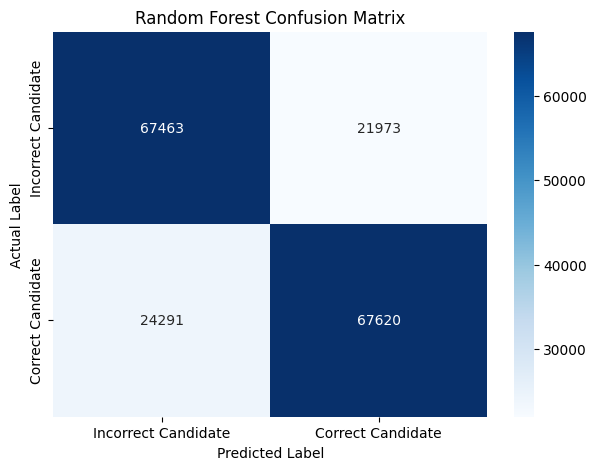

In [7]:
cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Incorrect Candidate", "Correct Candidate"],
    yticklabels=["Incorrect Candidate", "Correct Candidate"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Random Forest Confusion Matrix")
plt.show()

,Feature,Importance
4,heading_diff,0.322667
8,road_heading_sin,0.159344
5,prev_dist,0.119484
9,road_heading_cos,0.099209
2,speed,0.092822
0,distance_m,0.083475
6,heading_sin,0.047793
7,heading_cos,0.047474
1,rank,0.020541
3,time_gap,0.007192


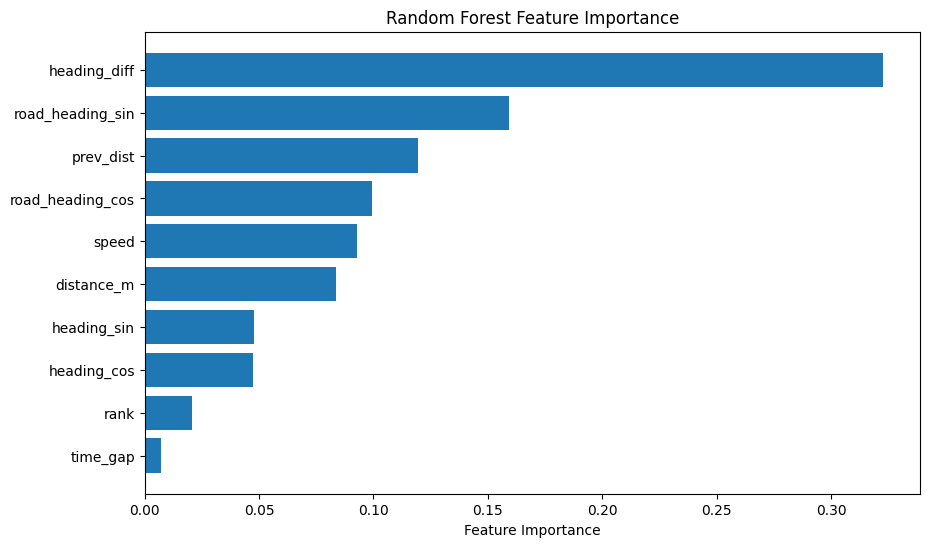

In [8]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

display(importance)

plt.figure(figsize=(10, 6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.title("Random Forest Feature Importance")
plt.show()

In [9]:
import joblib

joblib.dump(
    rf_model,
    "/kaggle/working/random_forest_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


Model Analysis: Random Forest
A. Model Understanding

* Why we considered this algorithm: Random Forest was selected to capture nonlinear relationships between GPS features and candidate road segments. Unlike Logistic Regression, which creates a linear decision boundary, Random Forest combines multiple decision trees to learn more complex patterns. We hypothesized that combinations of features such as distance_m, heading_diff, and speed could help distinguish correct road candidates more effectively.

* Strengths & Limitations: Its major strength is its ability to model nonlinear relationships and feature interactions without requiring extensive feature scaling. It also provides feature importance scores. However, Random Forest may produce less well-calibrated probabilities than Logistic Regression, which can affect the probability estimates used by the HMM Viterbi decoder.

B. Training and Configuration

* Hyperparameters:
- n_estimators=200 (number of decision trees).
- max_depth=20 (controls the maximum depth of each tree).
- min_samples_split=5 (minimum samples required to split a node).
- min_samples_leaf=2 (minimum samples required at a leaf node).
- max_features='sqrt' (number of features considered at each split).
- class_weight='balanced' (handles class imbalance).
* Objective: The model builds multiple decision trees using bootstrapped samples and combines their predictions through majority voting. It uses impurity-based splitting to identify useful feature divisions.

C. Experimental Results
- Accuracy: 84.67%
- Precision: 87.79%
- Recall: 77.53%
- F1-Score: 82.34%
* Confusion Matrix:
	Predicted 0	Predicted 1
Actual 0	2373	241
Actual 1	502	1732

* Overfitting/Underfitting: The validation accuracy of 84.67% indicates that the model captures useful patterns in the data. However, its recall of 77.53% shows that it misses some correct road candidates. Further comparison of training and validation performance would be required to determine whether overfitting is present.